# Serverledge — Esperimento V5: Random Forest 21 feature e nested group cross-validation

**Scopo:** valutare se modifiche **limitate** alla Random Forest migliorano la previsione dell'architettura per funzioni mai viste. Non modifichiamo i dati GCP e non utilizziamo GPU.

**Baseline paper-inspired:** 21 colonne nominali (due proxy ancora da verificare), Random Forest con **100 alberi**, classi `ARM-faster`, `ARM-slower`, `ARM-similar`, etichette già definite con soglia **±15%**, 100 campioni *warm* x86 per funzione, voto su 10/100 profili.

**Adattamento sperimentale, non attribuito agli autori:** `class_weight` e `min_samples_leaf` selezionati attraverso una **nested cross-validation** con gruppi di funzioni. Non selezioniamo feature o classi in base ai risultati del test.

**Progetto dei test:**
- **Esterna:** `StratifiedGroupKFold` a 5 fold × 2 ripetizioni (seed 42 e 137): stima out-of-fold, mai usata per scegliere iperparametri.
- **Interna:** `StratifiedGroupKFold` a 3 fold, effettuata *solo* sui gruppi di training esterni; sceglie la configurazione per **macro F1 su una predizione per funzione** (voto su 100 profili).
- **Controlli sugli identici fold esterni:** RF 21 standard, RF 19 standard, RF PAPER-6 standard, e predizione costante della maggioranza nel *solo training*.
- **Unità indipendente:** funzione/famiglia semantica, non la singola invocazione. Le varianti `-py`, `-node` e `twin-` sono tenute insieme.

I fold ripetuti non costituiscono nuove misure e non garantiscono un miglioramento. Il modello finale addestrato su tutte le 67 funzioni è **sperimentale**, non ha una nuova valutazione indipendente.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score, confusion_matrix
import sklearn

REL = Path("data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier")
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / REL / "diagnostica_21/paper_rf_dataset_21_proxy.csv").is_file()), None)
assert ROOT is not None, "Non trovo il CSV derivato dal notebook V4. Esegui prima la derivazione V4 nella root serverledge."
ANALYSIS = ROOT / REL
SOURCE = ROOT / "data/profiling/gcp-paper-rf-schema6/campaign/paper_rf_schema6_final/paper-rf-dataset.csv"
DATA21 = ANALYSIS / "diagnostica_21/paper_rf_dataset_21_proxy.csv"
AUDIT = ANALYSIS / "diagnostica_21/derivation_audit.json"
TRUTH = ANALYSIS / "paper_ground_truth.csv"
OUTPUT = ANALYSIS / "nested_cv_v5"
OUTPUT.mkdir(parents=True, exist_ok=True)
print("Repository:", ROOT)
print("Ambiente:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("CSV derivato:", DATA21)

Repository: /home/ale/Documenti/GitHub/serverledge
Ambiente: /home/ale/Documenti/GitHub/serverledge/.venv-analysis/bin/python3
scikit-learn: 1.9.0
CSV derivato: /home/ale/Documenti/GitHub/serverledge/data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier/diagnostica_21/paper_rf_dataset_21_proxy.csv


## 1. Congelare le condizioni sperimentali

Lasciamo **100 alberi** come nei precedenti esperimenti Serverledge, non cambiamo la soglia del paper e usiamo **tutte le 21 feature nominali** per il modello principale. Le due colonne `pageFaults` e `recommendedMemory` restano **proxy**: il loro nome non garantisce equivalenza con SAAF.

L'unico parametro strutturale addizionale oltre a `class_weight` è `min_samples_leaf=3` per una variante regolarizzata. I quattro candidati sono dichiarati **prima** di osservare i risultati esterni; l'ordinamento fisso risolve parità nella selezione.

In [2]:
SEED_MODEL = 42
N_TREES = 100
OUTER_SEEDS = (42, 137)  # 5 fold per ripetizione -> 10 valutazioni esterne
OUTER_SPLITS = 5
INNER_SPLITS = 3
CLASSES = ("ARM-faster", "ARM-slower", "ARM-similar")
FEATURES_21 = [
    "totalMemory", "freeMemory", "pageFaults", "frameworkRuntime", "userRuntime",
    "cpuUserDelta", "cpuNiceDelta", "cpuKernelDelta", "cpuIdleDelta",
    "cpuIOWaitDelta", "cpuIrqDelta", "cpuSoftIrqDelta", "cpuStealDelta",
    "cpuGuestDelta", "cpuGuestNiceDelta", "pageFaultsDelta", "availableCPUs",
    "utilizedCPUs", "recommendedMemory", "frameworkRuntimeDeltas", "runtime",
]
FEATURES_19 = [f for f in FEATURES_21 if f not in ("pageFaults", "recommendedMemory")]
FEATURES_6 = ["pageFaultsDelta", "utilizedCPUs", "freeMemory", "cpuUserDelta", "cpuKernelDelta", "frameworkRuntime"]
CANDIDATES = [
    {"name": "paper_default", "class_weight": None, "min_samples_leaf": 1},
    {"name": "balanced", "class_weight": "balanced", "min_samples_leaf": 1},
    {"name": "balanced_subsample", "class_weight": "balanced_subsample", "min_samples_leaf": 1},
    {"name": "balanced_leaf3", "class_weight": "balanced", "min_samples_leaf": 3},
]
print("Configurazioni pre-dichiarate:")
display(pd.DataFrame(CANDIDATES))
print("Fits CV interne previsti:", len(OUTER_SEEDS)*OUTER_SPLITS*INNER_SPLITS*len(CANDIDATES))
print("Tutti gli esperimenti restano locali e NON modificano il dataset GCP.")

Configurazioni pre-dichiarate:


,name,class_weight,min_samples_leaf
0,paper_default,NaN,1
1,balanced,balanced,1
2,balanced_subsample,balanced_subsample,1
3,balanced_leaf3,balanced,3


Fits CV interne previsti: 120
Tutti gli esperimenti restano locali e NON modificano il dataset GCP.


## 2. Caricamento e verifica dell'integrità

Viene controllato il checksum dell'originale rispetto al rapporto V4 e il checksum del derivato a 21 colonne. La *ground truth* resta quella già congelata: non ricalcoliamo le etichette usando dati dei fold di test.

In [3]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

assert all(p.is_file() for p in (DATA21, SOURCE, AUDIT, TRUTH)), "File di input mancante"
read_audit = json.loads(AUDIT.read_text(encoding="utf-8"))
assert sha256_file(SOURCE) == read_audit["input_sha256"], "Dataset schema 6 modificato dopo la derivazione"
assert sha256_file(DATA21) == read_audit["derived_sha256"], "Dataset derivato modificato dopo V4"
all_rows = pd.read_csv(DATA21)
truth = pd.read_csv(TRUTH)
assert len(all_rows) == 13400 and all_rows["request_id"].is_unique
assert truth["function_name"].is_unique and len(truth) == 67
assert set(FEATURES_21).issubset(all_rows.columns)
assert set(all_rows["machine_tag"]) == {"amd64", "arm64"}
assert all_rows.groupby(["machine_tag", "function_name"]).size().eq(100).all()
assert set(all_rows["function_name"]) == set(truth["function_name"])
assert truth["paper_class"].isin(CLASSES).all()
ref_v5 = all_rows[all_rows["machine_tag"] == "amd64"].copy()
ref_v5 = ref_v5.merge(truth[["function_name", "paper_class"]], on="function_name", validate="many_to_one")
assert len(ref_v5) == 6700
assert np.isfinite(ref_v5[FEATURES_21].to_numpy(dtype=float)).all()
ref_v5 = ref_v5.sort_values(["function_name", "request_id"], kind="stable").reset_index(drop=True)

def semantic_family_v5(name):
    s = str(name)
    if s.startswith("twin-"):
        s = s[len("twin-"):]
    s = re.sub(r"-(py|node)$", "", s)
    return re.sub(r"[^a-z0-9]+", "", s.lower())

x21 = ref_v5[FEATURES_21].to_numpy(dtype=float)
x19 = ref_v5[FEATURES_19].to_numpy(dtype=float)
x6 = ref_v5[FEATURES_6].to_numpy(dtype=float)
y = ref_v5["paper_class"].to_numpy()
groups = ref_v5["function_name"].map(semantic_family_v5).to_numpy()
fnames = ref_v5["function_name"].to_numpy()
assert len(set(groups)) >= OUTER_SPLITS
assert pd.Series(y).value_counts().ge(100).all()
assert ref_v5.groupby("function_name")["paper_class"].nunique().eq(1).all()
print("PASS: fonte e derivato SHA-256 verificati, 6700 profili x86 da 67 funzioni")
print("Famiglie semantiche:",len(set(groups)))
print("Classi (per funzione):")
display(ref_v5.groupby("function_name")["paper_class"].first().value_counts().rename("funzioni").to_frame())

PASS: fonte e derivato SHA-256 verificati, 6700 profili x86 da 67 funzioni
Famiglie semantiche: 44
Classi (per funzione):


,funzioni
paper_class,
ARM-similar,44
ARM-faster,14
ARM-slower,9


## 3. Metriche a livello di funzione e training

Per ogni funzione raccogliamo le 100 predizioni, calcoliamo il **voto sui primi 10** e il **voto su tutti i 100** profili. La metrica primaria del tuning è **macro F1 sulle 67 decisioni per funzione**, e non sui 6.700 campioni fortemente correlati. I gruppi sono verificati disgiunti ad ogni fold.

Nessun oversampling, SMOTE o leakage: i pesi `balanced` e `balanced_subsample` vengono calcolati solo sul training di ciascun fit.

In [4]:
def vote_one(predictions):
    counts = Counter(predictions)
    return min(CLASSES, key=lambda c: (-counts.get(c, 0), CLASSES.index(c)))

def per_function(idx, predictions):
    frame = pd.DataFrame({
        "function": fnames[idx], "true": y[idx], "pred": np.asarray(predictions, dtype=object),
    })
    records = []
    for fname, sub in frame.groupby("function", sort=True):
        assert len(sub) == 100, f"Attesi 100 profili: {fname}, presenti {len(sub)}"
        assert sub["true"].nunique() == 1
        records.append({
            "function": fname,
            "true": sub["true"].iloc[0],
            "vote10": vote_one(sub["pred"].iloc[:10].tolist()),
            "vote100": vote_one(sub["pred"].tolist()),
        })
    return pd.DataFrame(records)

def model_for(candidate):
    return RandomForestClassifier(
        n_estimators=N_TREES,
        random_state=SEED_MODEL,
        n_jobs=-1,
        class_weight=candidate["class_weight"],
        min_samples_leaf=candidate["min_samples_leaf"],
    )

def score_function_macro_f1(idx, pred):
    fn = per_function(idx, pred)
    return float(f1_score(fn["true"], fn["vote100"], labels=CLASSES,
                          average="macro", zero_division=0))

def select_by_inner_cv(training_ids, inner_seed, candidates=CANDIDATES):
    local_X, local_y, local_group = x21[training_ids], y[training_ids], groups[training_ids]
    splitter = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True,
                                   random_state=int(inner_seed))
    inner_folds = list(splitter.split(local_X, local_y, groups=local_group))
    scores = []
    for candidate in candidates:
        pred = np.empty(len(training_ids), dtype=object)
        for tr_local, val_local in inner_folds:
            assert set(local_group[tr_local]).isdisjoint(set(local_group[val_local]))
            assert len(set(local_y[tr_local])) >= 2, "Fold interno con meno di due classi"
            model = model_for(candidate)
            model.fit(local_X[tr_local], local_y[tr_local])
            pred[val_local] = model.predict(local_X[val_local])
        assert all(isinstance(p, str) for p in pred)
        scores.append({
            "candidate": candidate["name"],
            "inner_macroF1_funzione": score_function_macro_f1(training_ids, pred),
        })
    # In caso di parita' si preferisce il primo candidato, ossia la baseline non modificata.
    scores.sort(key=lambda r: -r["inner_macroF1_funzione"])
    chosen = next(c for c in candidates if c["name"] == scores[0]["candidate"])
    return chosen, scores

def evaluation(idx, pred, label, repeat):
    fn = per_function(idx, pred)
    truth_fn = fn["true"].to_numpy()
    predicted_fn = fn["vote100"].to_numpy()
    per_cls = recall_score(truth_fn, predicted_fn, labels=CLASSES, average=None, zero_division=0)
    return {
        "ripetizione": repeat, "metodo": label,
        "sample_accuracy": accuracy_score(y[idx], pred),
        "function_vote10_accuracy": accuracy_score(truth_fn, fn["vote10"]),
        "function_vote100_accuracy": accuracy_score(truth_fn, predicted_fn),
        "function_macroF1": f1_score(truth_fn, predicted_fn, labels=CLASSES,
                                      average="macro", zero_division=0),
        "function_balanced_accuracy": float(np.mean(per_cls)),
        **{f"recall_{cls}": float(v) for cls, v in zip(CLASSES, per_cls)},
    }, fn

print("Funzioni per l'esperimento pronte. Nessun training ancora eseguito.")

Funzioni per l'esperimento pronte. Nessun training ancora eseguito.


## 4. Esperimento principale: nested CV ripetuta

Si addestrano diversi modelli **solo in memoria**. Per ogni fold esterno, i pesi/parametri della RF-21 vengono selezionati usando soltanto i fold **interni**. Poi il modello scelto viene riaddestrato sui gruppi del training esterno e predice i gruppi esterni mai visti.

Per trasparenza, nella stessa partizione esterna addestriamo anche i controlli **RF-21 standard**, **RF-19 standard**, **RF-6 standard** e **classe maggioritaria del training**. Il confronto fra modelli è appaiato sugli stessi gruppi. Tutte le metriche sono salvate in una cartella di analisi separata.

In [5]:
METHODS = ("baseline_majority", "RF_6_default", "RF_19_default",
           "RF_21_default", "RF_21_nested_tuned")
fold_rows, score_rows, repeat_rows, function_rows = [], [], [], []
for repeat_n, outer_seed in enumerate(OUTER_SEEDS, start=1):
    splitter = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True,
                                   random_state=int(outer_seed))
    outer_folds = list(splitter.split(x21, y, groups=groups))
    oof = {name: np.empty(len(y), dtype=object) for name in METHODS}
    for fold_n, (tr, te) in enumerate(outer_folds, start=1):
        assert set(groups[tr]).isdisjoint(set(groups[te])), "LEAKAGE TRA FUNZIONI"
        assert len(set(y[tr])) == 3, "Training esterno senza una delle tre classi"
        chosen, inner_scores = select_by_inner_cv(tr, inner_seed=int(outer_seed*10 + fold_n))
        for rank, entry in enumerate(inner_scores, start=1):
            score_rows.append({"ripetizione": repeat_n, "fold": fold_n,
                               "rank":rank, **entry})
        xsets = {"RF_6_default": x6, "RF_19_default": x19,
                 "RF_21_default": x21, "RF_21_nested_tuned": x21}
        default = CANDIDATES[0]
        for method, features in xsets.items():
            params = chosen if method == "RF_21_nested_tuned" else default
            model = model_for(params)
            model.fit(features[tr], y[tr])
            oof[method][te] = model.predict(features[te])
        majority_train = pd.Series(y[tr]).value_counts().idxmax()
        oof["baseline_majority"][te] = majority_train
        fold_rows.append({"ripetizione":repeat_n, "seed_esterno":outer_seed,
                          "fold":fold_n, "funzioni_test":len(set(fnames[te])),
                          "famiglie_test":len(set(groups[te])),
                          "classe_maggioritaria_train":majority_train,
                          "parametri_scelti":chosen["name"],
                          "score_interno":inner_scores[0]["inner_macroF1_funzione"],
                          **{f"test_{c}": int((ref_v5.iloc[te].groupby("function_name")
                                                  ["paper_class"].first() == c).sum()) for c in CLASSES}})
        print(f"PASS — ripetizione {repeat_n}/{len(OUTER_SEEDS)}, fold {fold_n}/{OUTER_SPLITS}:"
              f" parametro interno={chosen['name']}, test={len(set(fnames[te]))} funzioni", flush=True)
    for method in METHODS:
        assert all(isinstance(x, str) for x in oof[method]), f"OOF incompleto per {method}"
        metrics, by_fn = evaluation(np.arange(len(y)), oof[method], method, repeat_n)
        repeat_rows.append(metrics)
        tmp = by_fn.copy()
        tmp["ripetizione"] = repeat_n
        tmp["metodo"] = method
        function_rows.append(tmp)

repeated_df = pd.DataFrame(repeat_rows)
fold_df = pd.DataFrame(fold_rows)
inner_df = pd.DataFrame(score_rows)
per_fn_df = pd.concat(function_rows, ignore_index=True)
assert repeated_df.shape[0] == len(OUTER_SEEDS)*len(METHODS)
assert per_fn_df.groupby(["metodo", "ripetizione"]).size().eq(67).all()
repeated_df.to_csv(OUTPUT / "nested_cv_per_repeat.csv", index=False)
fold_df.to_csv(OUTPUT / "nested_cv_outer_folds.csv", index=False)
inner_df.to_csv(OUTPUT / "nested_cv_inner_scores.csv", index=False)
per_fn_df.to_csv(OUTPUT / "nested_cv_predictions_per_function.csv", index=False)
print("PASS: CV esterna completata. Output:", OUTPUT)

PASS — ripetizione 1/2, fold 1/5: parametro interno=balanced_subsample, test=14 funzioni
PASS — ripetizione 1/2, fold 2/5: parametro interno=balanced_subsample, test=13 funzioni
PASS — ripetizione 1/2, fold 3/5: parametro interno=balanced, test=13 funzioni
PASS — ripetizione 1/2, fold 4/5: parametro interno=balanced, test=14 funzioni
PASS — ripetizione 1/2, fold 5/5: parametro interno=paper_default, test=13 funzioni
PASS — ripetizione 2/2, fold 1/5: parametro interno=paper_default, test=14 funzioni
PASS — ripetizione 2/2, fold 2/5: parametro interno=balanced_subsample, test=13 funzioni
PASS — ripetizione 2/2, fold 3/5: parametro interno=paper_default, test=13 funzioni
PASS — ripetizione 2/2, fold 4/5: parametro interno=paper_default, test=14 funzioni
PASS — ripetizione 2/2, fold 5/5: parametro interno=paper_default, test=13 funzioni
PASS: CV esterna completata. Output: /home/ale/Documenti/GitHub/serverledge/data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier/nested_cv_v5


## 5. Risultati e decisione preliminare

La **macro F1 per funzione** è la metrica primaria; l'accuratezza per funzione, il recall per ciascuna classe e l'accuratezza per campione sono secondari. Non consideriamo il 65,67% ottenuto sulla distribuzione globale come una baseline *di test* indipendente: confrontiamo la maggioranza **appresa nel training di ogni fold**.

Con due ripetizioni, la deviazione osservata fra seed è descrittiva, **non** un intervallo di confidenza. Nessun risultato qui è un test esterno definitivo su dati mai utilizzati nella ricerca.


Per ripetizione (percentuali):



Selezione dei parametri nei 10 fold esterni:


,fold
parametri_scelti,
paper_default,5
balanced_subsample,3
balanced,2



Classi nei fold esterni:


,ripetizione,fold,funzioni_test,parametri_scelti,test_ARM-faster,test_ARM-slower,test_ARM-similar
0,1,1,14,balanced_subsample,3,2,9
1,1,2,13,balanced_subsample,3,1,9
2,1,3,13,balanced,3,2,8
3,1,4,14,balanced,3,2,9
4,1,5,13,paper_default,2,2,9
5,2,1,14,paper_default,3,2,9
6,2,2,13,balanced_subsample,2,2,9
7,2,3,13,paper_default,3,1,9
8,2,4,14,paper_default,3,2,9
9,2,5,13,paper_default,3,2,8


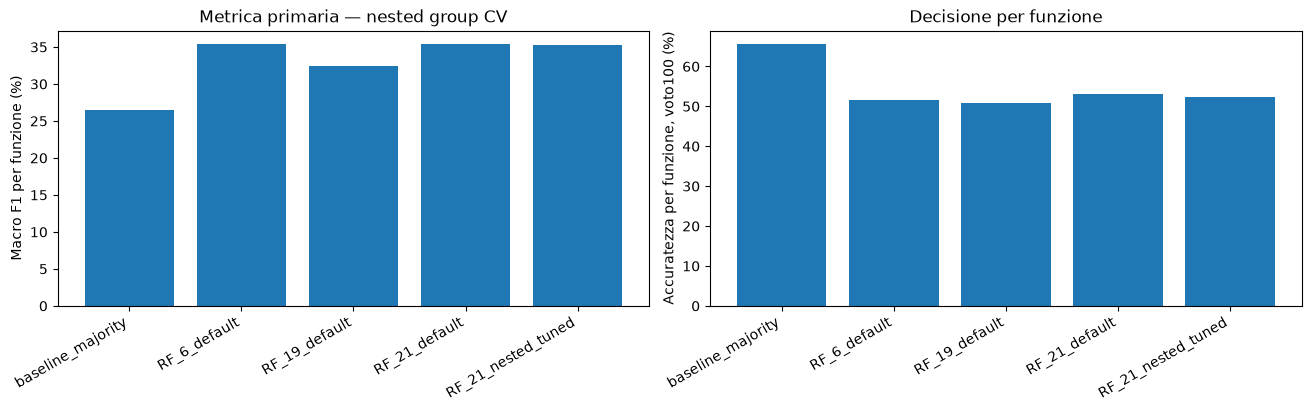

Differenza RF21 tuned - standard (macro F1): -0.15 punti percentuali
Differenza RF21 tuned - majority (macro F1): +8.86 punti percentuali
Non basta un aumento su pochi fold per concludere che il modello generalizzi meglio.


In [6]:
order = list(METHODS)
columns = ["function_macroF1", "function_vote100_accuracy", "function_vote10_accuracy",
           "sample_accuracy", "function_balanced_accuracy",
           *[f"recall_{c}" for c in CLASSES]]
summary = repeated_df.groupby("metodo", sort=False)[columns].agg(["mean", "std"]).reindex(order)
display(summary.style.format("{:.2%}"))
print("\nPer ripetizione (percentuali):")
display(repeated_df.set_index(["ripetizione", "metodo"])[columns].style.format("{:.2%}"))
print("\nSelezione dei parametri nei 10 fold esterni:")
display(fold_df["parametri_scelti"].value_counts().rename("fold").to_frame())
print("\nClassi nei fold esterni:")
display(fold_df[["ripetizione", "fold", "funzioni_test", "parametri_scelti",
                 *[f"test_{c}" for c in CLASSES]]])

fig, axes = plt.subplots(1, 2, figsize=(13,4), constrained_layout=True)
means = repeated_df.groupby("metodo").mean(numeric_only=True).reindex(order)
axes[0].bar(range(len(order)), 100*means["function_macroF1"].values)
axes[0].set_xticks(range(len(order)), order, rotation=30, ha="right")
axes[0].set_ylabel("Macro F1 per funzione (%)")
axes[0].set_title("Metrica primaria — nested group CV")
axes[1].bar(range(len(order)), 100*means["function_vote100_accuracy"].values)
axes[1].set_xticks(range(len(order)), order, rotation=30, ha="right")
axes[1].set_ylabel("Accuratezza per funzione, voto100 (%)")
axes[1].set_title("Decisione per funzione")
plt.show()

baseline_f1 = means.loc["RF_21_default", "function_macroF1"]
tuned_f1 = means.loc["RF_21_nested_tuned", "function_macroF1"]
majority_f1 = means.loc["baseline_majority", "function_macroF1"]
print(f"Differenza RF21 tuned - standard (macro F1): {100*(tuned_f1-baseline_f1):+.2f} punti percentuali")
print(f"Differenza RF21 tuned - majority (macro F1): {100*(tuned_f1-majority_f1):+.2f} punti percentuali")
print("Non basta un aumento su pochi fold per concludere che il modello generalizzi meglio.")

## 6. Modello finale sperimentale: tuning grouped CV, refit su tutte le 67 funzioni

**Passaggio separato dalla valutazione nested precedente.** Dopo aver misurato la procedura di selezione dei parametri, scegliamo la configurazione usando **una grouped 3-fold CV sul corpus di training completo** e riaddestriamo su tutti i 6.700 profili x86. Salvata in un percorso nuovo: **non sostituisce il modello V2.1**.

Il modello finale non è stato valutato su un ulteriore dataset esterno: il risultato da riportare nella tesi rimane la **nested CV esterna**, non la prestazione dei dati usati per il refit.

Se la procedura di tuning non migliora la baseline, il modello sarà comunque etichettato come **esperimentale**: non implementarlo nel load balancer senza una verifica ulteriore.

In [7]:
import joblib

all_index = np.arange(len(y))
final_params, final_scores = select_by_inner_cv(all_index, inner_seed=2026)
final_model = model_for(final_params)
final_model.fit(x21, y)
model_path = OUTPUT / "rf21_experimental_model.joblib"
joblib.dump(final_model, model_path)
metadata = {
    "status": "experimental_not_deployed",
    "description": "Random Forest 21 nominal features, two SAAF proxies not semantically verified",
    "source_sha256": sha256_file(SOURCE),
    "derived21_sha256": sha256_file(DATA21),
    "ground_truth_sha256": sha256_file(TRUTH),
    "sklearn_version": sklearn.__version__,
    "model_random_state": SEED_MODEL,
    "n_estimators": N_TREES,
    "feature_order": FEATURES_21,
    "class_order": list(CLASSES),
    "labeling": "ground truth per-function from paper_ground_truth.csv, threshold ±15%",
    "outer_seeds": list(OUTER_SEEDS),
    "outer_folds": OUTER_SPLITS,
    "inner_folds": INNER_SPLITS,
    "grouping": "twin- prefix and -py/-node suffix stripped; remove separators",
    "primary_metric": "macro F1 per-function vote100",
    "chosen_final_parameters": final_params,
    "final_inner_cv_scores": final_scores,
    "test_warning": "Nested outer CV estimates procedure; final refit has no independent external test",
}
(OUTPUT / "model_metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
summary.reset_index().to_csv(OUTPUT / "nested_cv_summary_means_std.csv", index=False)
print("PASS: modello sperimentale salvato:", model_path)
print("Parametro scelto tramite CV su tutte le funzioni:", final_params)
print("Risultati CV esterna e metadata salvati in", OUTPUT)
print("ATTENZIONE: Non sovrascrive V2.1; non dichiara prestazioni indipendenti sul refit finale.")

PASS: modello sperimentale salvato: /home/ale/Documenti/GitHub/serverledge/data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier/nested_cv_v5/rf21_experimental_model.joblib
Parametro scelto tramite CV su tutte le funzioni: {'name': 'paper_default', 'class_weight': None, 'min_samples_leaf': 1}
Risultati CV esterna e metadata salvati in /home/ale/Documenti/GitHub/serverledge/data/profiling/gcp-paper-rf-schema6/analysis/paper-rf-classifier/nested_cv_v5
ATTENZIONE: Non sovrascrive V2.1; non dichiara prestazioni indipendenti sul refit finale.


## 7. Come interpretare l'esperimento

1. **Confronto corretto:** priorità al confronto *appaiato* `RF_21_nested_tuned` vs `RF_21_default` sugli stessi fold esterni. Guardare macro F1 per funzione **e** recall delle classi rare; un'accuratezza più alta accompagnata da recall quasi nullo non è un miglioramento utile.
2. **Bilanciamento:** se `balanced`/`balanced_subsample` migliora il recall delle classi minoritarie a costo di qualche errore sulla classe `ARM-similar`, valutarne la convenienza nello scheduling. Non inseguire la sola accuratezza.
3. **Controlli delle feature:** le 19 feature senza proxy e le sei importanti del paper servono da riferimento *non ottimizzato*; un eventuale vantaggio del modello a 21 feature deve essere verificato contro questi controlli.
4. **Limiti del dataset:** 67 funzioni, una configurazione per funzione, profili della stessa funzione dipendenti, etichette vicine alla soglia, differenze semantiche SAAF non ancora del tutto validate. Le 21 colonne nominali non equivalgono ancora a una replica SAAF perfetta.
5. **Passo successivo:** leggere `nested_cv_per_repeat.csv`, `nested_cv_outer_folds.csv` e `model_metadata.json`; solo allora decidere se usare il modello sperimentale o mantenere quello originale come baseline e procedere ai regressori ARM-speed.